In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import matplotlib.dates as mdates

def moving_average(x, delta, edges='repeat'):
    '''Calculate moving average of data array x. Average goes from i-delta to i+delta for every i.
    The argument edges determines how the edge of the array is treated. Options are:
        'repeat': First or last value is repeated beyond array. Output array has same length as input array.
        'cut': Input array is not extended for averaging. Output array has length N-2*delta, where N is len(x).
        'wrap': Input array wraps around for averaging. Output array has same length as input array.'''
    
    N = len(x)
    
    filtered_array = np.zeros(N)
    
    if edges == 'repeat':
        # Original data starts at index delta, stops at delta+N-1
        padded_array = np.concatenate([
            np.ones(delta) * x[0],  # repeat first value at start
            x,
            np.ones(delta) * x[-1]  # repeat last value at end
        ])
    elif edges == 'cut':
        # We pad with zeros to be able to treat this case the same as the others while averaging.
        # We need to cut the start and end of the array before returing it.
        padded_array = np.concatenate([
            np.zeros(delta),
            x,
            np.zeros(delta)
        ])
    elif edges == 'wrap':
        padded_array = np.concatenate([
            x[-delta:],
            x,
            x[:delta]
        ])
    else:
        raise ValueError('Invalid argument edges="{}"'.format(edges))

    # Calculate moving average
    for i in range(N):
        filtered_array[i] = np.mean(padded_array[i:i+2*delta])

    # Cut invalid parts in case edges='repeat'
    if edges == 'cut':
        filtered_array = filtered_array[delta:-delta]
        
    return filtered_array


In [47]:
df_bab = pd.read_csv("bab_el_mandeb_arrivals.csv")
df_cape = pd.read_csv("cape_arrivals.csv")
df_bab["DateTime"] = pd.to_datetime(df_bab["DateTime"])
df_cape["DateTime"] = pd.to_datetime(df_cape["DateTime"])
df_cape.head()


,DateTime,Container,Dry Bulk,General Cargo,Roll-on/roll-off,Tanker,7-day Moving Average,Prior Year: 7-day Moving Average
0,2019-01-01,8,25,3,2,12,NaN,NaN
1,2019-01-02,3,8,8,1,4,NaN,NaN
2,2019-01-03,7,37,2,2,16,NaN,NaN
3,2019-01-04,7,21,2,1,11,NaN,NaN
4,2019-01-05,5,31,3,3,22,NaN,NaN


In [48]:
ship_types = ["Container", "Dry Bulk", "General Cargo", "Roll-on/roll-off", "Tanker"]

df_bab["total"] = df_bab[ship_types].sum(axis=1)
df_cape["total"] = df_cape[ship_types].sum(axis=1)

In [49]:
df_bab_23_on = df_bab[df_bab["DateTime"] >= "2023-01-01"]
df_cape_23_on = df_cape[df_cape["DateTime"] >= "2023-01-01"]
df_cape_23_on.head()

,DateTime,Container,Dry Bulk,General Cargo,Roll-on/roll-off,Tanker,7-day Moving Average,Prior Year: 7-day Moving Average,total
1461,2023-01-01,4,26,6,2,9,38.428571,43.428571,47
1462,2023-01-02,6,28,1,0,10,38.857143,42.428571,45
1463,2023-01-03,2,27,1,0,9,39.428571,42.857143,39
1464,2023-01-04,7,32,2,1,10,42.571429,42.571429,52
1465,2023-01-05,4,23,0,2,5,42.000000,42.857143,34


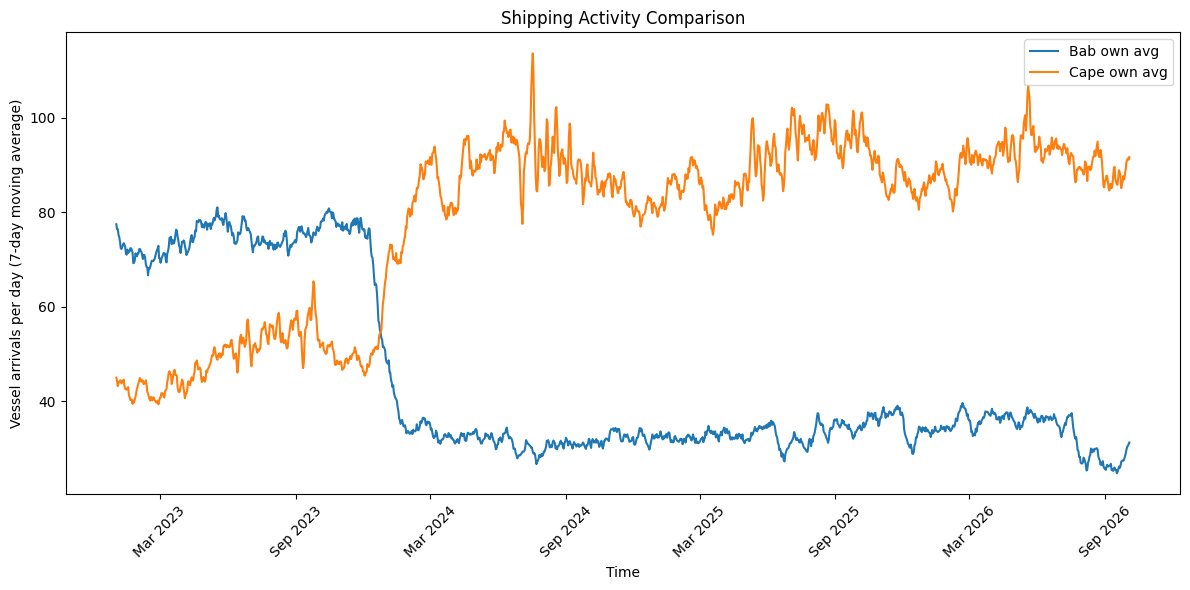

In [50]:
bab_datetime = pd.to_datetime(df_bab_23_on["DateTime"])
cape_datetime = pd.to_datetime(df_cape_23_on["DateTime"])

bab_tot = df_bab_23_on["total"].to_numpy()
cape_tot = df_cape_23_on["total"].to_numpy()

bab7avg = df_bab_23_on["7-day Moving Average"]
cape7avg = df_cape_23_on["7-day Moving Average"]
cape7avg_own = moving_average(cape_tot, delta=7, edges="repeat")
bab7avg_own = moving_average(bab_tot, delta=7, edges="repeat")

plt.figure(figsize=(12, 6))

#plt.plot(bab_datetime, bab7avg, label="Bab el-Mandeb")
plt.plot(bab_datetime, bab7avg_own, label="Bab own avg")
#plt.plot(cape_datetime, cape7avg, label="Cape of Good Hope")
plt.plot(cape_datetime, cape7avg_own, label="Cape own avg")

plt.xlabel("Time")
plt.ylabel("Vessel arrivals per day (7-day moving average)")
plt.title("Shipping Activity Comparison")
plt.legend()

# Show one x-axis label every 6 months
ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

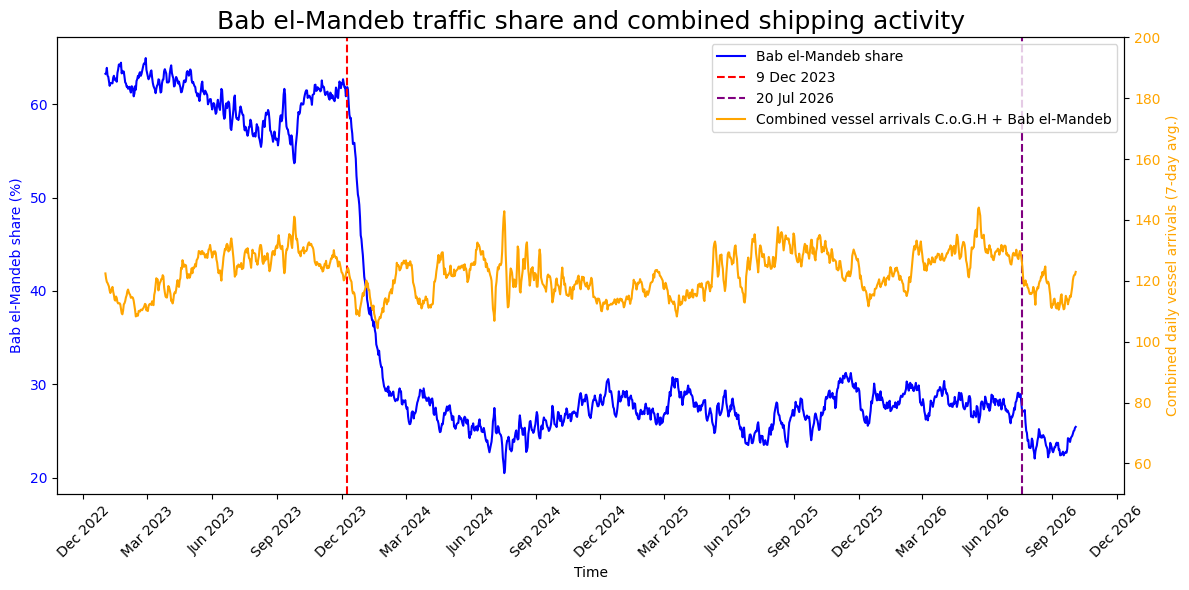

In [60]:

event = pd.Timestamp("2023-12-09")
event2 = pd.Timestamp("2026-07-20")

#ratio_bab = bab_tot / (bab_tot + cape_tot)
#ratio_cape = cape_tot / (bab_tot + cape_tot)

avg_ratio_bab = bab7avg_own/(bab7avg_own + cape7avg_own) * 100
avg_ratio_cape = cape7avg_own/(bab7avg_own + cape7avg_own) * 100
avg_tot = bab7avg_own + cape7avg_own

#bab14avg = moving_average(bab_tot, delta=14)
#cape14avg = moving_average(cape_tot, delta=14)



fig, ax1 = plt.subplots(figsize=(12, 6))

# Left y-axis: Bab el-Mandeb share
ax1.plot(
    bab_datetime, avg_ratio_bab,
    label="Bab el-Mandeb share",
    linestyle="-",
    color="blue"
)
ax1.set_ylabel("Bab el-Mandeb share (%)", color="blue")
ax1.tick_params(axis="y", labelcolor="blue")

# Right y-axis: Combined vessel arrivals
ax2 = ax1.twinx()

ax2.plot(
    bab_datetime, avg_tot,
    label="Combined vessel arrivals C.o.G.H + Bab el-Mandeb",
    color="orange"
)
ax2.set_ylabel("Combined daily vessel arrivals (7-day avg.)", color="orange")
ax2.tick_params(axis="y", labelcolor="orange")

# Event marker
ax1.axvline(
    event, color="red", linestyle="--",
    label="9 Dec 2023"
)

ax1.axvline(
    event2, color="purple", linestyle="--",
    label="20 Jul 2026"
)

# Formatting
ax1.set_xlabel("Time")
ax1.set_title("Bab el-Mandeb traffic share and combined shipping activity", size=18)

ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax2.set_ylim(50,200)

# Combine legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")
ax1.tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.show()


## November23 crisis 

In [52]:
event = pd.Timestamp("2023-12-09")
#event = pd.Timestamp("2026-09-11")

before_start = event - pd.Timedelta(days=70)
after_end = event + pd.Timedelta(days=70)

bab_before = df_bab[
    (df_bab["DateTime"] >= before_start) &
    (df_bab["DateTime"] < event)
]

cape_before = df_cape[
    (df_cape["DateTime"] >= before_start) &
    (df_cape["DateTime"] < event)
]

# Post-crisis period
bab_after = df_bab[(df_bab["DateTime"] >= event) & (df_bab["DateTime"] < after_end)]
cape_after = df_cape[(df_cape["DateTime"] >= event) & (df_cape["DateTime"] < after_end)]

bab_before_mean = bab_before["total"].mean()
bab_after_mean = bab_after["total"].mean()

cape_before_mean = cape_before["total"].mean()
cape_after_mean = cape_after["total"].mean()

bab_change = 100 * (bab_after_mean / bab_before_mean - 1)
cape_change = 100 * (cape_after_mean / cape_before_mean - 1)

print(f"Bab el-Mandeb: {bab_change:.1f}%")
print(f"Cape of Good Hope: {cape_change:.1f}%")

Bab el-Mandeb: -41.5%
Cape of Good Hope: 38.2%


## 2026 anouncements

In [53]:
event = pd.Timestamp("2026-07-20")
#event = pd.Timestamp("2026-09-11")

before_start = event - pd.Timedelta(days=70)
after_end = event + pd.Timedelta(days=70)

bab_before = df_bab[(df_bab["DateTime"] >= before_start) & (df_bab["DateTime"] < event)]
cape_before = df_cape[(df_cape["DateTime"] >= before_start) & (df_cape["DateTime"] < event)]

bab_after = df_bab[(df_bab["DateTime"] >= event) & (df_bab["DateTime"] < after_end)]
cape_after = df_cape[(df_cape["DateTime"] >= event) & (df_cape["DateTime"] < after_end)]

bab_before_mean = bab_before["total"].mean()
bab_after_mean = bab_after["total"].mean()

cape_before_mean = cape_before["total"].mean()
cape_after_mean = cape_after["total"].mean()

bab_change = 100 * (bab_after_mean / bab_before_mean - 1)
cape_change = 100 * (cape_after_mean / cape_before_mean - 1)

print(f"Bab el-Mandeb: {bab_change:.1f}%")
print(f"Cape of Good Hope: {cape_change:.1f}%")

Bab el-Mandeb: -24.9%
Cape of Good Hope: -6.2%


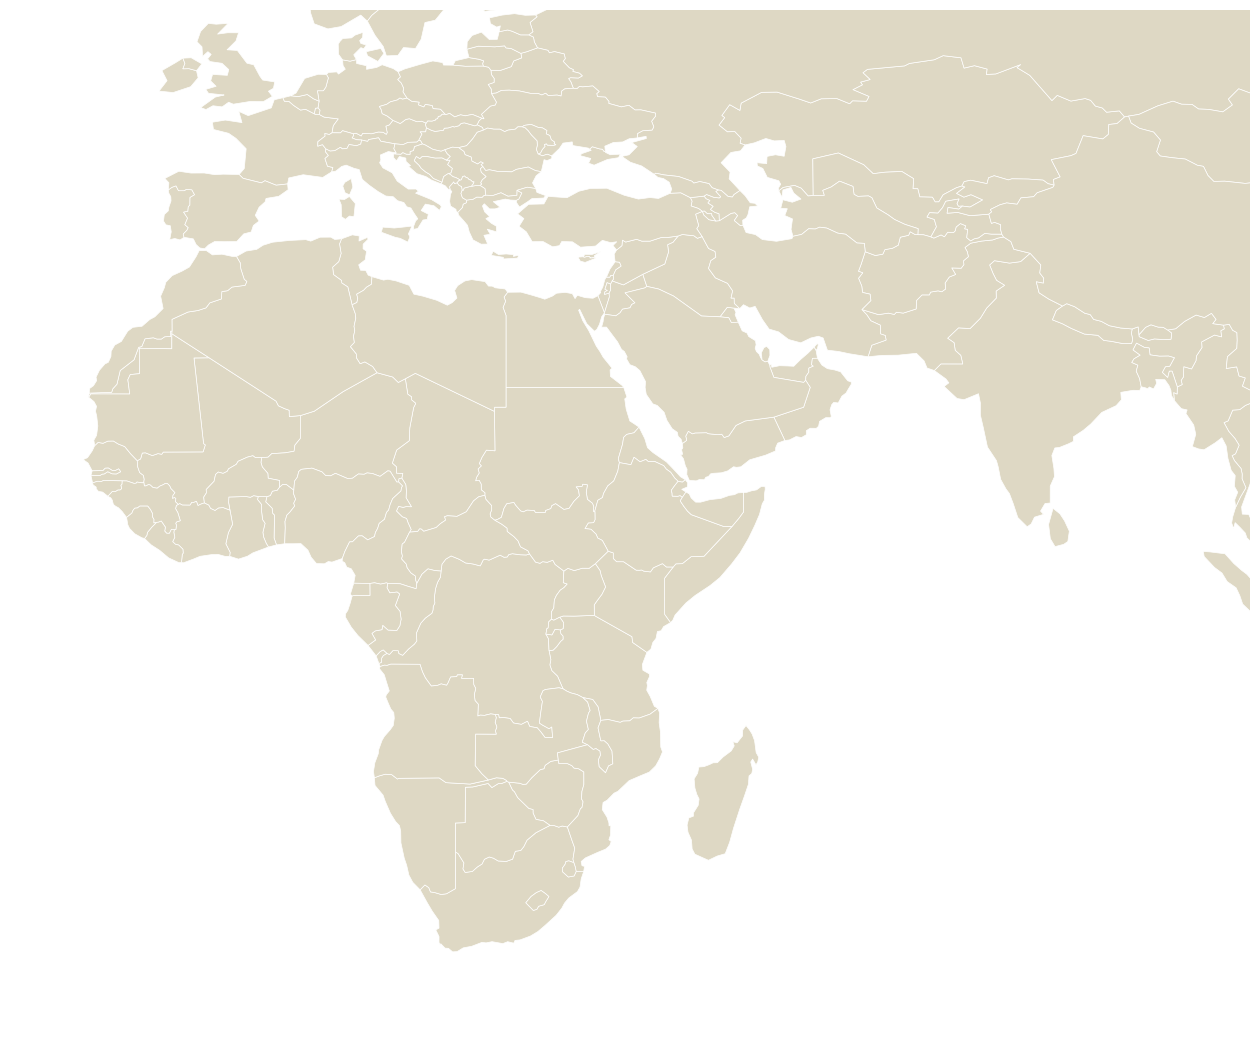

In [54]:
world = gpd.read_file(
    "map/ne_110m_admin_0_countries.shp"
)

fig, ax = plt.subplots(figsize=(16, 16))

world.plot(
    ax=ax,
    facecolor="#ded8c4",
    edgecolor="white",
    linewidth=0.5
)

ax.set_xlim(-25, 100)
ax.set_ylim(-45, 60)
ax.axis("off")


plt.savefig(
    "red_sea_basemap.svg",
    bbox_inches="tight",
    transparent=True
)